# Trabalho Prático: Clusterização com Spark ML
**Disciplina:** Processamento de Dados Massivos — IESB  
**Professor:** Alexandre Roriz  
**Tema Sorteado:** Clusterização

## 1. Contextualização

### 1.1. Escolha da Base e Amostragem
A base pública de corridas dos táxis amarelos de Nova York (*Yellow Taxi Trip Records*), disponibilizada pela prefeitura da cidade (NYC TLC). Cada linha da tabela é uma viagem real registrada pelos taxímetros.

* **Fonte Pública Oficial:** [NYC Taxi and Limousine Commission (TLC)](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page)
* **Arquivo utilizado (Janeiro/2024):** `https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet`
* **Volume de Dados:** Só o arquivo bruto de janeiro de 2024 tem **2.964.624 registros** e **19 colunas** (a série histórica inteira da TLC passa de 1,5 bilhão de viagens). Depois de aplicar os cortes de limpeza que mostro na seção 3, sobraram **2.639.343 viagens válidas**. A partir dessa base limpa, tirei uma amostra aleatória simples sem reposição de 15% (`fraction=0.15`, `seed=42`), fechando meu dataset final de trabalho com **396.672 registros** — quase o dobro do mínimo de 200 mil linhas exigido para o trabalho.

### 1.2. Dicionário das Colunas Originais

| Coluna | Tipo | Descrição Prática |
| :--- | :--- | :--- |
| `VendorID` | Inteiro | Empresa fornecedora do taxímetro (`1` = Creative Mobile; `2` = VeriFone). |
| `tpep_pickup_datetime` | Data/Hora | Data e hora do início da corrida. |
| `tpep_dropoff_datetime` | Data/Hora | Data e hora do fim da corrida. |
| `passenger_count` | Inteiro | Número de passageiros na viagem. |
| `trip_distance` | Decimal | Distância percorrida em milhas medida pelo taxímetro. |
| `RatecodeID` | Inteiro | Código da tarifa (`1` = Padrão Urbano; `2` = JFK; `3` = Newark; `4` = Fora da cidade; `5` = Negociada; `6` = Grupo). |
| `store_and_fwd_flag` | Texto | Indica se a corrida ficou guardada na memória do carro por falta de sinal antes de subir para o servidor (`Y`/`N`). |
| `PULocationID` | Inteiro | ID da zona onde o passageiro embarcou (*Pick-Up*). |
| `DOLocationID` | Inteiro | ID da zona onde o passageiro desembarcou (*Drop-Off*). |
| `payment_type` | Inteiro | Meio de pagamento (`1` = Cartão; `2` = Dinheiro; `3` = Sem cobrança; `4` = Disputa; `5` = Desconhecido; `6` = Cancelada). |
| `fare_amount` | Decimal | Tarifa base cobrada pelo tempo e distância (em USD). |
| `extra` | Decimal | Adicionais de horário de pico (1.00) e turno noturno (0.50). |
| `mta_tax` | Decimal | Imposto municipal fixo de 0.50 (MTA). |
| `tip_amount` | Decimal | Gorjeta em dólares (registrada automaticamente nos pagamentos com cartão). |
| `tolls_amount` | Decimal | Valor gasto com pedágios durante o trajeto. |
| `improvement_surcharge` | Decimal | Taxa fixa de 1.00 para manutenção viária. |
| `total_amount` | Decimal | Valor total cobrado do passageiro. |
| `congestion_surcharge` | Decimal | Taxa de congestionamento para viagens no centro de Manhattan. |
| `Airport_fee` | Decimal | Taxa fixa de 1.75 para embarques nos aeroportos LaGuardia e JFK. |

### 1.3. Pergunta de Negócio
> **"Quais são os perfis reais de operação dos táxis em Nova York considerando distância, tempo no trânsito, velocidade média, horário e custos, e como usar esses grupos para distribuir melhor os carros na rua e ajustar a operação por turno?"**

### 1.4. Por que tive que usar PySpark neste problema?
Tentar fazer essa limpeza e rodar a busca de hiperparâmetros do K-Means no `pandas` / `scikit-learn` estava esgotando a RAM do ambiente:

**Estouro de Memória na Limpeza e Codificação:** Carregar quase 3 milhões de linhas em memória local, converter timestamps, filtrar outliers e rodar `drop_duplicates` em múltiplas colunas consome vários gigabytes num único processo. Quando tentei aplicar One-Hot Encoding e padronizar as matrizes no Pandas, o uso de RAM multiplicou até derrubar o kernel.

Treinar o K-Means de $k=2$ até $k=6$ exige varrer a base dezenas de vezes seguidas, e validar os grupos em quase 400 mil linhas exige milhões de cálculos de distância euclidiana. No PySpark, resolvi isso particionando o processamento entre os núcleos e travando o DataFrame pré-processado em memória com `.cache()`, sem precisar reler o arquivo do disco a cada rodada.

## 2. Ingestão dos Dados e Definição Manual do Schema

Nos meus primeiros testes de carga da base da TLC, deixar o Spark descobrir a tipagem sozinho (`inferSchema`) gerou dois problemas práticos: primeiro, ele precisava varrer os 2,96 milhões de registros antes de montar o DataFrame, deixando a leitura muito lenta; segundo, ele falhava ou tipava errado colunas com muitos nulos (`passenger_count` e `RatecodeID` têm mais de 140 mil nulos e vinham como `Double` em vez de inteiro) além de dar conflito de timezone nas datas `tpep_pickup_datetime` e `tpep_dropoff_datetime`, que exigem `TimestampNTZType`.

Por isso, escrevi o `StructType` na mão e forcei o schema direto na leitura.

In [1]:
import urllib.request
import os
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, IntegerType, LongType,
    DoubleType, StringType, TimestampNTZType
)

# Aumentei a memória do driver para 4g porque nos primeiros testes com os 2.96M de registros o Spark estava engasgando
spark = SparkSession.builder \
    .appName("SparkML_Clusterizacao_NYCTaxi") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

url = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
caminho_arquivo = "yellow_tripdata_2024-01.parquet"

if not os.path.exists(caminho_arquivo):
    print("Baixando a base de dados da fonte original...")
    urllib.request.urlretrieve(url, caminho_arquivo)
    print("Download concluído!")

# escrever o StructType na mão porque o inferSchema era lento demais em quase 3M de linhas
# e falhava na tipagem das datas sem fuso (TimestampNTZType) e nas colunas inteiras cheias de nulos
schema_taxi = StructType([
    StructField("VendorID", IntegerType(), True),
    StructField("tpep_pickup_datetime", TimestampNTZType(), True),
    StructField("tpep_dropoff_datetime", TimestampNTZType(), True),
    StructField("passenger_count", LongType(), True),
    StructField("trip_distance", DoubleType(), True),
    StructField("RatecodeID", LongType(), True),
    StructField("store_and_fwd_flag", StringType(), True),
    StructField("PULocationID", IntegerType(), True),
    StructField("DOLocationID", IntegerType(), True),
    StructField("payment_type", LongType(), True),
    StructField("fare_amount", DoubleType(), True),
    StructField("extra", DoubleType(), True),
    StructField("mta_tax", DoubleType(), True),
    StructField("tip_amount", DoubleType(), True),
    StructField("tolls_amount", DoubleType(), True),
    StructField("improvement_surcharge", DoubleType(), True),
    StructField("total_amount", DoubleType(), True),
    StructField("congestion_surcharge", DoubleType(), True),
    StructField("Airport_fee", DoubleType(), True)
])

df_bruto = spark.read.schema(schema_taxi).parquet(caminho_arquivo)

total_bruto = df_bruto.count()
print(f"Total de registros originais: {total_bruto:,}")
print(f"Total de colunas: {len(df_bruto.columns)}")
df_bruto.printSchema()
df_bruto.show(5, truncate=False)

Baixando a base de dados da fonte original...
Download concluído!
Total de registros originais: 2,964,624
Total de colunas: 19
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)

## 3. Exploração Passo a Passo e Limpeza dos Dados

### 3.1. Inspeção Inicial da Base Bruta
Rodei o `.describe()` nas colunas numéricas e contei os valores nulos para ver o estado real dos 2,96 milhões de registros brutos.

In [2]:
#VERIFICAR min, max, média e desvio padrão para mapear erros de taxímetro/GPS
colunas_analise = ["passenger_count", "trip_distance", "fare_amount", "tip_amount", "tolls_amount", "total_amount"]
print("--- Estatísticas Descritivas (Dados Brutos) ---")
df_bruto.select(colunas_analise).describe().show()

#VERIFICAR a quantidade de nulos nas variáveis principais
print("--- Contagem de Valores Nulos ---")
df_bruto.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in colunas_analise + ["RatecodeID", "payment_type"]]).show()

--- Estatísticas Descritivas (Dados Brutos) ---
+-------+------------------+------------------+------------------+------------------+------------------+------------------+
|summary|   passenger_count|     trip_distance|       fare_amount|        tip_amount|      tolls_amount|      total_amount|
+-------+------------------+------------------+------------------+------------------+------------------+------------------+
|  count|           2824462|           2964624|           2964624|           2964624|           2964624|           2964624|
|   mean|1.3392808966805005|3.6521691789580624|18.175061916792536| 3.335870015894562|0.5270212040366137| 26.80150477092493|
| stddev|0.8502816924800862|225.46257238220082|18.949547705905324|3.8965505998067607|2.1283096763989033|23.385577429672043|
|    min|                 0|               0.0|            -899.0|             -80.0|             -80.0|            -900.0|
|    max|                 9|          312722.3|            5000.0|             428.0

### 3.2. Análise das Anomalias Encontradas e Regras de Corte
A saída acima revelou vários problemas graves que puxariam os centróides do K-Means para lugares sem sentido se não limpasse antes:
1. **Valores Nulos Cravados:** `passenger_count` e `RatecodeID` têm  **140.162 linhas nulas** cada. São viagens em que o taxímetro falhou ao gravar os parâmetros básicos, então usei `.dropna()` para descartá-las.
2. **Outliers absurdos de GPS (`trip_distance`):** Enquanto a média é 3,65 milhas, o máximo bateu **312.722,3 milhas**, jogando o desvio padrão para **225,46** (além de corridas zeradas com `0.0`). Travei a distância entre **0,2 e 60 milhas**.
3. **Estornos e cobranças irreais (`fare_amount` e `total_amount`):** Apareceram tarifas negativas de até **-899,00** (estornos de maquininha) e cobranças de **5.000,00** numa única corrida. Filtrei `fare_amount` entre **3,00 e 250,00**, exigindo também `tip_amount >= 0` e `tolls_amount >= 0`.
4. **Passageiros e Tempo de Corrida:** Existem carros com `0` ou `9` passageiros, além de viagens com duração zerada/negativa ou taxímetros esquecidos ligados por horas. Criei `duracao_min` e mantive apenas **1 a 6 passageiros** e durações de **1 a 180 minutos**.
5. **Filtro Operacional e Duplicatas:** foi mantida só as tarifas principais (`RatecodeID` 1, 2 e 3: Urbana, JFK e Newark) e pagamentos válidos (`payment_type` 1 e 2: Cartão e Dinheiro, descartando disputas/cancelamentos). Na sequência, apliquei `.dropDuplicates()` na chave composta de datas, zonas e valor para remover viagens enviadas duas vezes pelo aparelho.

In [3]:
#Criar duração em minutos, remover os 140.162 nulos, filtrar outliers e tirar duplicatas
df_limpo = df_bruto.withColumn(
    "duracao_min",
    (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60.0
).dropna(subset=["passenger_count", "RatecodeID", "payment_type", "trip_distance", "fare_amount"]) \
 .filter(
    (F.col("passenger_count") >= 1) & (F.col("passenger_count") <= 6) &
    (F.col("trip_distance") >= 0.2) & (F.col("trip_distance") <= 60.0) &
    (F.col("duracao_min") >= 1.0) & (F.col("duracao_min") <= 180.0) &
    (F.col("fare_amount") >= 3.0) & (F.col("fare_amount") <= 250.0) &
    (F.col("tip_amount") >= 0.0) & (F.col("tolls_amount") >= 0.0) &
    (F.col("RatecodeID").isin([1, 2, 3])) &      # Padrão Urbano, 2: JFK, 3: Newark
    (F.col("payment_type").isin([1, 2]))         # Cartão, 2: Dinheiro
).dropDuplicates(["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "total_amount"])

total_limpo = df_limpo.count()
print(f"Total de registros após limpeza e remoção de duplicatas: {total_limpo:,}")

Total de registros após limpeza e remoção de duplicatas: 2,639,343


### 3.3. Amostragem e Validação Pós-Limpeza
Dos **2.639.343 registros** que sobraram após a limpeza, extraí a amostra de 15% (`seed=42`) com `.cache()`, gerando **396.672 linhas**. Rodei um novo `.describe()` abaixo para checar o efeito dos cortes: o desvio padrão de `trip_distance` despencou de **225,46** para **4,18**, mantendo as médias preservadas.

In [4]:
# Amostragem de 15% (Mais ou menos 396 mil registros) em cache e checagem final com .describe()
df_amostra = df_limpo.sample(withReplacement=False, fraction=0.15, seed=42).cache()
print(f"Total de registros na amostra final de trabalho: {df_amostra.count():,}")

print("--- Estatísticas Descritivas (Dados Limpos) ---")
df_amostra.select(colunas_analise + ["duracao_min"]).describe().show()

Total de registros na amostra final de trabalho: 396,672
--- Estatísticas Descritivas (Dados Limpos) ---
+-------+------------------+-----------------+------------------+-----------------+------------------+------------------+------------------+
|summary|   passenger_count|    trip_distance|       fare_amount|       tip_amount|      tolls_amount|      total_amount|       duracao_min|
+-------+------------------+-----------------+------------------+-----------------+------------------+------------------+------------------+
|  count|            396672|           396672|            396672|           396672|            396672|            396672|            396672|
|   mean|1.3566120119393352|3.186141219949983| 17.87054400108907|3.518687832768633|0.5240020974507924|26.909528502137782|14.564528460121544|
| stddev| 0.848678543099965|  4.1860261785715|15.612126127179987| 3.75029148522389| 2.018018915254422|20.310195057383005|10.982115468970283|
|    min|                 1|              0.2|   

## 4. Engenharia de Atributos e Pipeline

Para que o agrupamento pegasse a dinâmica real do trânsito de Nova York em vez de olhar só para o preço da corrida, criei variáveis operacionais antes de montar o `Pipeline` do Spark ML:

* **`velocidade_media_mph`:** Dividi a distância pelo tempo em horas (com limite de segurança `<= 75 mph` para eliminar saltos residuais de antena de GPS). Criei essa coluna porque uma corrida de 3 milhas feita a 8 mph no congestionamento do centro é operacionalmente muito diferente de 3 milhas feitas a 25 mph na madrugada.
* **`periodo_dia`:**  a hora de embarque ficou em 4 faixas (`Manha`, `Tarde`, `Noite` e `Madrugada`).
* **`tipo_tarifa`:** Agrupei o `RatecodeID` em `Urbana_Padrao` (código 1) e `Aeroporto` (códigos 2 e 3, referentes a JFK e Newark).

**Por que cortei `total_amount` e IDs de zonas do vetor:** Deixei `total_amount` de fora do `VectorAssembler` porque já passo `fare_amount`, `tip_amount` e `tolls_amount`; colocar a soma junto dobraria o peso do dinheiro na distância. Também descartei `PULocationID` e `DOLocationID` porque têm mais de 260 bairros diferentes, o que abriria mais de 500 colunas binárias no `OneHotEncoder` e estragaria o cálculo de distância.

In [5]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler

# Criação de Colunbas velocidade, turno e tipo de tarifa
df_features = df_amostra.withColumn(
    "velocidade_media_mph",
    F.round(F.col("trip_distance") / (F.col("duracao_min") / 60.0), 2)
).filter(F.col("velocidade_media_mph") <= 75.0) \
 .withColumn("hora", F.hour("tpep_pickup_datetime")) \
 .withColumn(
    "periodo_dia",
    F.when((F.col("hora") >= 6) & (F.col("hora") < 12), "Manha")
     .when((F.col("hora") >= 12) & (F.col("hora") < 18), "Tarde")
     .when((F.col("hora") >= 18) & (F.col("hora") <= 23), "Noite")
     .otherwise("Madrugada")
).withColumn(
    "tipo_tarifa",
    F.when(F.col("RatecodeID") == 1, "Urbana_Padrao").otherwise("Aeroporto")
)

colunas_categoricas = ["periodo_dia", "tipo_tarifa"]
indexadas = [c + "_idx" for c in colunas_categoricas]
codificadas = [c + "_ohe" for c in colunas_categoricas]

indexer = StringIndexer(inputCols=colunas_categoricas, outputCols=indexadas, handleInvalid="keep")
encoder = OneHotEncoder(inputCols=indexadas, outputCols=codificadas, dropLast=True)

colunas_numericas = [
    "trip_distance", "duracao_min", "velocidade_media_mph",
    "fare_amount", "tip_amount", "tolls_amount", "passenger_count"
]

assembler = VectorAssembler(
    inputCols=colunas_numericas + codificadas,
    outputCol="features_raw"
)

# Padronização necessária para impedir que fare_amount (até 250) engula variáveis menores como passenger_count (1 a 6)
scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withMean=True,
    withStd=True
)

# Rodo o pipeline de preparação antes do loop de k para colocar o vetor pronto em .cache()
pipeline_prep = Pipeline(stages=[indexer, encoder, assembler, scaler])
modelo_prep = pipeline_prep.fit(df_features)
df_preparado = modelo_prep.transform(df_features).cache()

df_preparado.select("trip_distance", "duracao_min", "periodo_dia", "tipo_tarifa", "features").show(5, truncate=False)

+-------------+------------------+-----------+-------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|trip_distance|duracao_min       |periodo_dia|tipo_tarifa  |features                                                                                                                                                                                                                                                                |
+-------------+------------------+-----------+-------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|20.93        |52.9166

## 5. Modelagem (K-Means) e Escolha Prática do $k$

Testei valores de $k$ de **2 até 6** em cima do `df_preparado`. Os números saíram assim:
* **$k = 2$:** Inércia de `3.548.583,88` | Silhueta de `0.8609`
* **$k = 3$:** Inércia de `2.981.349,05` | Silhueta de `0.3314`
* **$k = 4$:** Inércia de `2.448.697,46` | Silhueta de `0.4819`
* **$k = 5$:** Inércia de `1.950.783,50` | Silhueta de `0.5460`
* **$k = 6$:** Inércia de `1.528.715,57` | Silhueta de `0.6559`

### Por que escolhi $k = 4$?
Se  olhar só para a Silhueta isolada, pegaria $k = 2$ (`0.8609`). O problema é que, para o negócio, dividir Nova York inteira em 2 grupos é inútil: o modelo só separa os 4% de corridas longas de aeroporto de um lado e joga os outros 96% de viagens urbanas num único grupo gigante, mantendo uma Inércia muito alta (`3,54 milhões`).

Quando se passa para $k = 3$, a Silhueta cai (`0.3314`) porque o K-Means começa a quebrar o bloco urbano, mas em **$k = 4$** a curva de Inércia acumula uma queda forte de **1,1 milhão de pontos** (`2,44 milhões`) e a Silhueta dá um salto de restaurar para **`0.4819`**. Escolhi **$k = 4$** porque é exatamente o ponto da curva onde consigo separar a operação urbana nos 3 regimes reais de trânsito (manhã, gargalo da tarde e noite livre) mais a operação dedicada de aeroportos, sem quebrar os dados demais.

Testando diferentes valores de k...
k = 2 | Inércia (WSSE): 3,548,583.88 | Índice de Silhueta: 0.8609
k = 3 | Inércia (WSSE): 2,981,349.05 | Índice de Silhueta: 0.3314
k = 4 | Inércia (WSSE): 2,448,697.46 | Índice de Silhueta: 0.4819
k = 5 | Inércia (WSSE): 1,950,783.50 | Índice de Silhueta: 0.5460
k = 6 | Inércia (WSSE): 1,528,715.57 | Índice de Silhueta: 0.6559


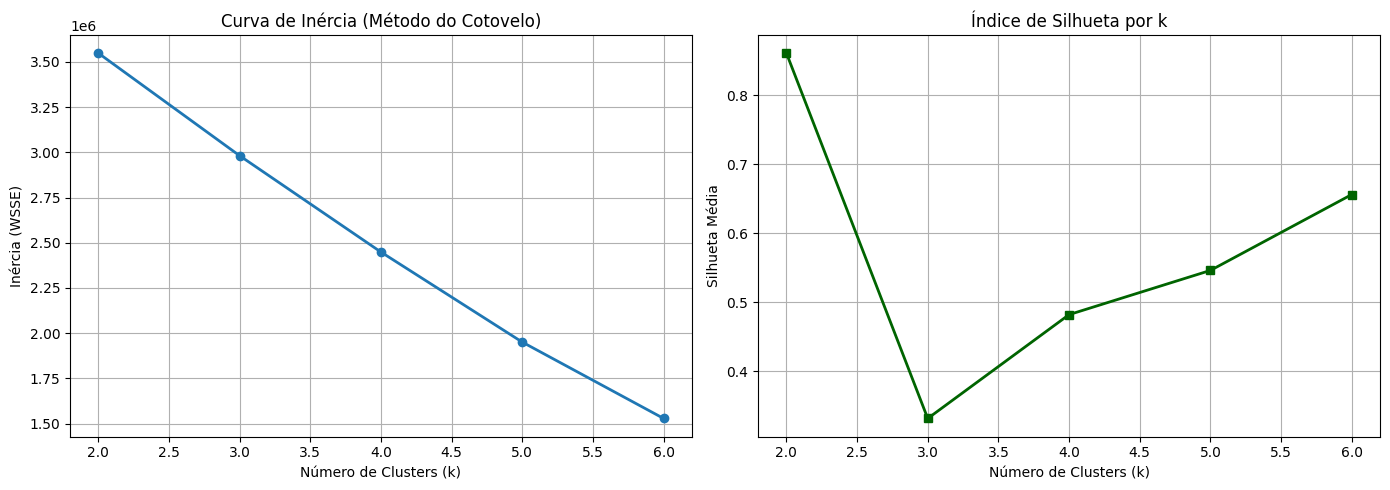

In [6]:
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
import matplotlib.pyplot as plt

valores_k = [2, 3, 4, 5, 6]
inercia_wsse = []
silhuetas = []

evaluator = ClusteringEvaluator(
    predictionCol="prediction",
    featuresCol="features",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

print("Testando diferentes valores de k...")
for k in valores_k:
    kmeans = KMeans(featuresCol="features", predictionCol="prediction", k=k, seed=42, maxIter=30)
    modelo_k = kmeans.fit(df_preparado)

    custo = modelo_k.summary.trainingCost
    inercia_wsse.append(custo)

    predicoes_k = modelo_k.transform(df_preparado)
    score_silhueta = evaluator.evaluate(predicoes_k)
    silhuetas.append(score_silhueta)

    print(f"k = {k} | Inércia (WSSE): {custo:,.2f} | Índice de Silhueta: {score_silhueta:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(valores_k, inercia_wsse, marker='o', linewidth=2)
ax[0].set_title("Curva de Inércia (Método do Cotovelo)")
ax[0].set_xlabel("Número de Clusters (k)")
ax[0].set_ylabel("Inércia (WSSE)")
ax[0].grid(True)

ax[1].plot(valores_k, silhuetas, marker='s', color='darkgreen', linewidth=2)
ax[1].set_title("Índice de Silhueta por k")
ax[1].set_xlabel("Número de Clusters (k)")
ax[1].set_ylabel("Silhueta Média")
ax[1].grid(True)

plt.tight_layout()
plt.show()

In [7]:
# Agrupei todos os estágios (StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler e KMeans k=4)
# num único Pipeline completo para treinar o modelo definitivo e exportar depois
k_escolhido = 4
kmeans_final = KMeans(featuresCol="features", predictionCol="cluster", k=k_escolhido, seed=42, maxIter=50)

pipeline_completo = Pipeline(stages=[indexer, encoder, assembler, scaler, kmeans_final])
modelo_final = pipeline_completo.fit(df_features)

df_resultado = modelo_final.transform(df_features)

print("--- PERFIL MÉDIO DE CADA CLUSTER ---")
perfil_clusters = df_resultado.groupBy("cluster").agg(
    F.count("*").alias("total_corridas"),
    F.round(F.mean("trip_distance"), 2).alias("dist_media_mi"),
    F.round(F.mean("duracao_min"), 2).alias("duracao_media_min"),
    F.round(F.mean("velocidade_media_mph"), 2).alias("velocidade_mph"),
    F.round(F.mean("fare_amount"), 2).alias("tarifa_media_usd"),
    F.round(F.mean("tip_amount"), 2).alias("gorjeta_media_usd"),
    F.round(F.mean("tolls_amount"), 2).alias("pedagio_medio_usd"),
    F.round(F.mean("passenger_count"), 2).alias("passageiros_medio")
).orderBy("cluster")

perfil_clusters.show(truncate=False)

print("--- DISTRIBUIÇÃO POR TIPO DE TARIFA E CLUSTER ---")
df_resultado.groupBy("cluster", "tipo_tarifa").count().orderBy("cluster", "tipo_tarifa").show()

print("--- DISTRIBUIÇÃO POR PERÍODO DO DIA E CLUSTER ---")
df_resultado.groupBy("cluster", "periodo_dia").count().orderBy("cluster", "periodo_dia").show()

--- PERFIL MÉDIO DE CADA CLUSTER ---
+-------+--------------+-------------+-----------------+--------------+----------------+-----------------+-----------------+-----------------+
|cluster|total_corridas|dist_media_mi|duracao_media_min|velocidade_mph|tarifa_media_usd|gorjeta_media_usd|pedagio_medio_usd|passageiros_medio|
+-------+--------------+-------------+-----------------+--------------+----------------+-----------------+-----------------+-----------------+
|0      |83959         |2.45         |13.25            |10.68         |15.4            |2.98             |0.3              |1.29             |
|1      |143760        |2.38         |14.0             |9.49          |15.51           |3.11             |0.29             |1.35             |
|2      |15988         |18.51        |44.68            |26.86         |72.69           |12.39            |6.52             |1.54             |
|3      |152960        |2.75         |12.67            |12.07         |15.71           |3.27             

## 6. Avaliação Prática: Perfil de Negócio e Limitações

### 6.1. Perfil de Negócio dos 4 Clusters

* **Cluster 0 — Deslocamento Individual da Manhã (`83.959 corridas` | 21,2% da amostra):**
  * **Perfil:** 100% concentrado na **Manhã** e tarifa **Urbana Padrão**. Viagens curtas (**2,45 milhas** em **13,25 min**, velocidade de **10,68 mph**), tarifa média de **$15,40** e a menor média de passageiros da base (**1,29**). É o perfil clássico de quem sai sozinho de casa ou das estações de trem/metrô para o escritório.
  * **Impacto de Negócio:** Exige posicionar a frota cedo (6h às 9h) nas zonas residenciais (Upper East/West Side) e ao redor da Penn Station e Grand Central.

* **Cluster 1 — Gargalo Crítico da Tarde (`143.760 corridas` | 36,2% da amostra):**
  * **Perfil:** Concentra as corridas urbanas da **Tarde**. Apesar de ter a **menor distância média** entre todos os grupos (**2,38 milhas**), tem a **maior duração urbana** (**14,00 min**), derrubando a velocidade média para **9,49 mph** (a mais travada da cidade).
  * **Impacto de Negócio:** Como os carros ficam presos no congestionamento de Midtown, a oferta de táxis livres cai exatamente quando a demanda aumenta. Precisa de reforço de frota no centro comercial à tarde e compensação tarifária por minuto parado para o motorista não evitar a região.

* **Cluster 2 — Conexão Aeroportos e Longa Distância (`15.988 corridas` | 4,0% da amostra):**
  * **Perfil:** Reúne quase todas as corridas de **Aeroporto (JFK/Newark)** (`14.579`) mais `1.409` viagens longas pela tarifa comum, espalhadas por todos os turnos (com maior volume à tarde, `6.913`, e à noite, `4.894`). A distância média salta para **18,51 milhas**, duração de **44,68 min** e velocidade alta de **26,86 mph** por vias expressas. O ticket é quase 5 vezes maior: tarifa base média de **$72,69**, gorjeta de **$12,39**, pedágio médio de **$6,52** e a maior ocupação (**1,54 passageiros**, comum em viagens com família e malas).
  * **Impacto de Negócio:** Apesar de representar só 4% das viagens, puxa uma fatia enorme da receita e das gorjetas. Justifica fila dedicada de carros com porta-malas grande nos terminais do JFK e Newark principalmente entre 12h e 22h, além de despacho casado (embarque e desembarque) para o motorista não bater lata vazio na volta.

* **Cluster 3 — Alto Giro de Noite e Madrugada (`152.960 corridas` | 38,6% da amostra):**
  * **Perfil:** Maior grupo em volume, somando as viagens urbanas da **Noite** (`126.087`) e **Madrugada** (`26.873`). Com as avenidas livres, os carros rodam distâncias maiores que durante o dia (**2,75 milhas**) em menos tempo (**12,67 min**), batendo a melhor velocidade urbana (**12,07 mph**), maior tarifa urbana (**$15,71**) e melhor gorjeta urbana (**$3,27**).
  * **Impacto de Negócio:** É o turno de maior giro por hora trabalhada em Manhattan (regiões de restaurantes, teatros e vida noturna). Vale criar incentivo para manter os motoristas rodando depois das 20h.

### 6.2. Limitações Reais do Modelo
* **Peso inflado das variáveis binárias no `StandardScaler`:** Como eu passei o vetor inteiro pelo `StandardScaler(withMean=True, withStd=True)`, as variáveis binárias (0 e 1) geradas pelo `OneHotEncoder` para `periodo_dia` foram escalonadas pelo desvio padrão e ganharam um peso alto na distância euclidiana. Isso forçou os 3 clusters urbanos (0, 1 e 3) a se dividirem exatamente pelos turnos do dia. Para corrigir isso, eu teria que aplicar o `StandardScaler` apenas nas 7 variáveis numéricas contínuas antes de juntá-las com as dummies no `VectorAssembler`.
* **Subestimação de gorjetas em dinheiro:** Nas corridas pagas em dinheiro (`payment_type = 2`), o taxímetro registra `tip_amount = 0.0`, o que joga a média de gorjeta dos clusters um pouco abaixo do valor real recebido pelo motorista.
* **Viés Sazonal de Inverno:** Como processei apenas janeiro de 2024, o frio intenso de Nova York infla o volume de corridas curtíssimas (menos de 2 milhas) que em meses mais quentes seriam feitas a pé ou de metrô.

## 7. Persistência do Modelo

Na última célula abaixo, salvo o `modelo_final` completo (contendo todas as etapas do `Pipeline` de pré-processamento e o `KMeans` treinado com $k=4$) usando o método `.save()` do Spark ML.

In [8]:
caminho_modelo = "modelo_sparkml_kmeans_nyctaxi"

# Persistência do PipelineModel completo em disco usando o método save() do Spark ML
modelo_final.write().overwrite().save(caminho_modelo)
print(f"Modelo Pipeline salvo com sucesso em: '{caminho_modelo}'")

Modelo Pipeline salvo com sucesso em: 'modelo_sparkml_kmeans_nyctaxi'
